In [5]:
import networkx as nx
from networkx.algorithms import bipartite
import matplotlib.pyplot as plt

In [7]:
## Importing and Exploring the Data


G = nx.davis_southern_women_graph()
women = G.graph["top"]
events = G.graph["bottom"]
print(len(women), "women", len(events), "events",
      G.number_of_edges(), "attendances")

18 women 14 events 89 attendances


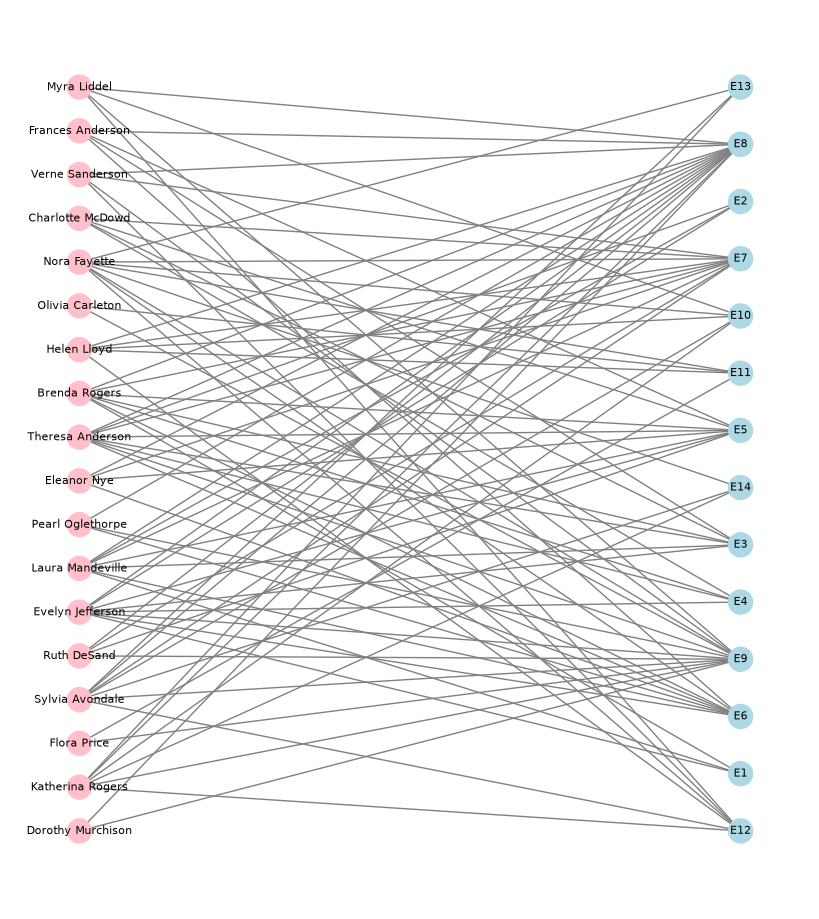

In [8]:
## Look at the Raw Network, 2- mode Picture

pos = nx.bipartite_layout(G, women)
colors = ["pink" if n in women else "lightblue" for n in G]
plt.figure(figsize=(8, 9))
nx.draw(G, pos, with_labels=True, node_color=colors, font_size=8, edge_color="gray")
plt.show()

In [9]:
## Counts
## This lets us see simiple data such as: who is most social? which evetns are the biggest by number of attendees?


print("EVENTS ATTENDED BY EACH WOMAN")
for w in sorted(women, key=G.degree, reverse=True):
    print(w, G.degree(w))

print()
print("WOMEN AT EACH EVENT")
for e in sorted(events, key=G.degree, reverse=True):
    print(e, G.degree(e))

EVENTS ATTENDED BY EACH WOMAN
Evelyn Jefferson 8
Theresa Anderson 8
Nora Fayette 8
Laura Mandeville 7
Brenda Rogers 7
Sylvia Avondale 7
Katherina Rogers 6
Helen Lloyd 5
Charlotte McDowd 4
Frances Anderson 4
Eleanor Nye 4
Ruth DeSand 4
Verne Sanderson 4
Myra Liddel 4
Pearl Oglethorpe 3
Dorothy Murchison 2
Olivia Carleton 2
Flora Price 2

WOMEN AT EACH EVENT
E8 14
E9 12
E7 10
E5 8
E6 8
E3 6
E12 6
E10 5
E4 4
E11 4
E1 3
E2 3
E13 3
E14 3


In [10]:
## Relationships between the women
## 2 women who attended the same event most probably know each other, we want to explore these relationships between the women. This allows us to determine weight in linkage between women. 

W = bipartite.weighted_projected_graph(G, women)
E = bipartite.weighted_projected_graph(G, events)

print("Women network:", W.number_of_edges(), "links out of", 18 * 17 // 2, "possible")
print("Events network:", E.number_of_edges(), "links out of", 14 * 13 // 2, "possible")
print("Evelyn and Theresa went to", W["Evelyn Jefferson"]["Theresa Anderson"]["weight"], "events together")

Women network: 139 links out of 153 possible
Events network: 66 links out of 91 possible
Evelyn and Theresa went to 7 events together


In [11]:
## Relationships between the Friend Groups
## This allows us to frind grouping between the women and who is the most connected in these groups:Evelyn, Theresa, nora, and sylvia all have groups around them 

women_groups = nx.community.greedy_modularity_communities(W, weight="weight")
for i, g in enumerate(women_groups, start=1):
    print("Women group", i, ":", sorted(g))

print()
event_groups = nx.community.greedy_modularity_communities(E, weight="weight")
for i, g in enumerate(event_groups, start=1):
    print("Event group", i, ":", sorted(g))

Women group 1 : ['Dorothy Murchison', 'Flora Price', 'Helen Lloyd', 'Katherina Rogers', 'Myra Liddel', 'Nora Fayette', 'Olivia Carleton', 'Pearl Oglethorpe', 'Sylvia Avondale', 'Verne Sanderson']
Women group 2 : ['Brenda Rogers', 'Charlotte McDowd', 'Eleanor Nye', 'Evelyn Jefferson', 'Frances Anderson', 'Laura Mandeville', 'Ruth DeSand', 'Theresa Anderson']

Event group 1 : ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8']
Event group 2 : ['E10', 'E11', 'E12', 'E13', 'E14', 'E9']


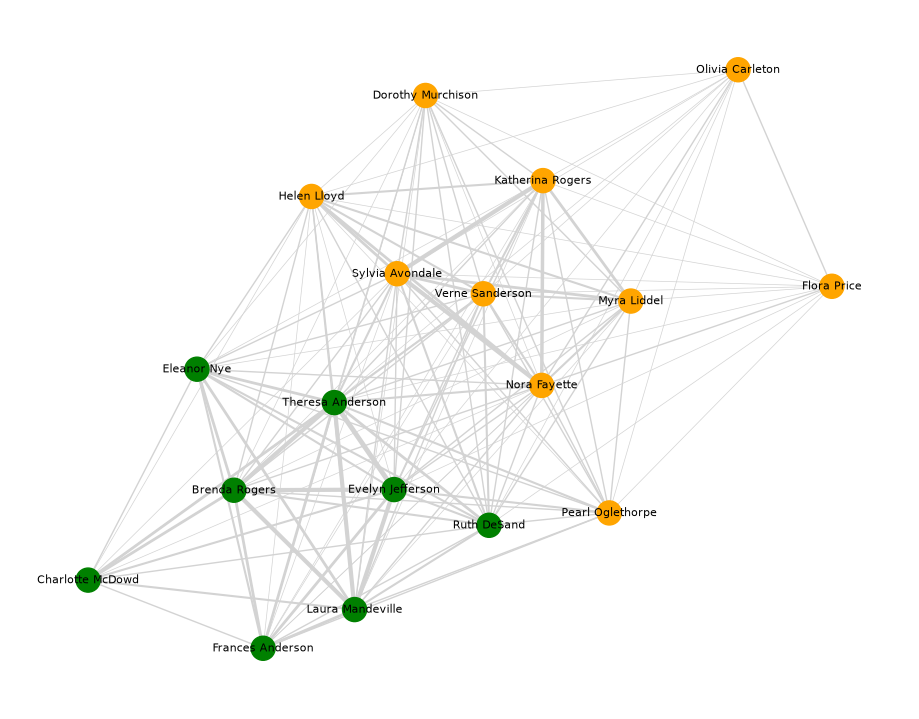

In [12]:
## Group Picture
## Visual representation of the groups
colors = ["orange" if w in women_groups[0] else "green" for w in W]
widths = [W[u][v]["weight"] / 2 for u, v in W.edges()]
plt.figure(figsize=(9, 7))
nx.draw(W, nx.spring_layout(W, seed=1), with_labels=True, node_color=colors,
        width=widths, edge_color="lightgray", font_size=8)
plt.show()

In [13]:
## The Social Events
for e in events:
    g1 = len([w for w in G[e] if w in women_groups[0]])
    g2 = len([w for w in G[e] if w in women_groups[1]])
    print(e, "  group 1 (orange):", g1, "  group 2 (green):", g2)

E1   group 1 (orange): 0   group 2 (green): 3
E2   group 1 (orange): 0   group 2 (green): 3
E3   group 1 (orange): 0   group 2 (green): 6
E4   group 1 (orange): 0   group 2 (green): 4
E5   group 1 (orange): 0   group 2 (green): 8
E6   group 1 (orange): 2   group 2 (green): 6
E7   group 1 (orange): 4   group 2 (green): 6
E8   group 1 (orange): 7   group 2 (green): 7
E9   group 1 (orange): 9   group 2 (green): 3
E10   group 1 (orange): 5   group 2 (green): 0
E11   group 1 (orange): 4   group 2 (green): 0
E12   group 1 (orange): 6   group 2 (green): 0
E13   group 1 (orange): 3   group 2 (green): 0
E14   group 1 (orange): 3   group 2 (green): 0


In [ ]:
## The inferences we can make about the women and the events

# There are 2 friend groups, The green group centers around Evelyn, Theresa, Lausa, and Brenda
# The Orange group centers around Nora, Sylvia, Katherina, and Helen. This is visually transparent with the weight by thick lines. Women in the same friend group share the same events that they attend.
# Almost all the women are connected in some way, this is most probably from major events where they may have met with each other, so the events that are shared between women are very importatnt in their relationship

# For the events we can see there are 2 sets, created by the 2 different friend groups, each respective group attended certain events. E6-E9 were a collaboration between both groups and you see the intermixing of connections there
# Larger Events show more intermixing and smaller events show less due to smaller circles attending these events. 

